# Step 7b: Alternative causal graphs, nested time-series tuning, calibration, saved models
Run Steps 1 to 6 first. Needs `monthly_panel_with_hormuz_state.csv` in `MyDrive/Dataset`. Runtime: about 1 to 3 minutes. Saved models go to `MyDrive/Dataset/models/`.

In [1]:
import pandas as pd, numpy as np
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/My Work/Research/AI+ BBA/Supply Chain_GNN/Dataset'

Mounted at /content/drive


## 1. Setup

In [2]:
import statsmodels.api as sm, matplotlib.pyplot as plt, os, json, joblib, warnings, time
from scipy.stats import rankdata
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import log_loss
warnings.filterwarnings("ignore")
rng = np.random.default_rng(11)
panel = pd.read_csv(f"{BASE}/monthly_panel_with_hormuz_state.csv")
panel["month"] = pd.PeriodIndex(panel["month"], freq="M"); panel = panel.set_index("month").sort_index().loc[:"2026-09"]
D = pd.DataFrame({"g": panel["gscpi"], "lb": np.log(panel["brent"]), "oni": panel["oni"]})
D["dg"] = D.g.diff(); D["db"] = D.lb.diff(); D["oni_l1"] = D.oni.shift(1); D["dg_next"] = D.dg.shift(-1); D["db_next"] = D.db.shift(-1)
H = 3

## 2. Alternative causal graphs (section 11: sensitivity to alternative dags)

In [3]:
SPECS = {"G1 baseline DAG": dict(g=["dg", "g", "db", "oni_l1"], b=["db", "dg", "oni_l1"]),
         "G2 no direct ENSO->GSCPI": dict(g=["dg", "g", "db"], b=["db", "dg", "oni_l1"]),
         "G3 Brent does not mediate (no Brent->GSCPI)": dict(g=["dg", "g", "oni_l1"], b=["db", "dg", "oni_l1"]),
         "G4 no GSCPI->Brent feedback": dict(g=["dg", "g", "db", "oni_l1"], b=["db", "oni_l1"]),
         "G5 no ENSO anywhere": dict(g=["dg", "g", "db"], b=["db", "dg"])}
def fit_spec(spec, end):
    need = list(set(spec["g"] + spec["b"])) + ["dg_next", "db_next"]; s = D.loc["1999-01":end].dropna(subset=need)
    mg = sm.OLS(s.dg_next, sm.add_constant(s[spec["g"]])).fit(); mb = sm.OLS(s.db_next, sm.add_constant(s[spec["b"]])).fit()
    return mg, mb, np.column_stack([mg.resid.values, mb.resid.values])
def sim_spec(row, h, spec, mg, mb, res, n=250, oni_path=None, force_brent=None):
    idx = rng.integers(0, len(res), size=(n, h)); G = np.full(n, row["g"]); DG = np.full(n, row["dg"]); DB = np.full(n, row["db"]); LB = np.zeros(n)
    bg = np.full(n, -np.inf); bb = np.full(n, -np.inf)
    for k in range(h):
        o = oni_path[k] if oni_path is not None else row["oni_l1"]; st = {"dg": DG, "g": G, "db": DB, "oni_l1": o}; e = res[idx[:, k]]
        dgn = mg.params["const"] + sum(mg.params[v] * st[v] for v in spec["g"]) + e[:, 0]
        dbn = mb.params["const"] + sum(mb.params[v] * st[v] for v in spec["b"]) + e[:, 1]
        if force_brent is not None and k in force_brent: dbn = np.full(n, force_brent[k])
        G = G + dgn; LB = LB + dbn; DG, DB = dgn, dbn; bg = np.maximum(bg, G - row["g"]); bb = np.maximum(bb, np.exp(LB) - 1)
    return bg, bb

def auc(y, s):
    r = rankdata(s); n1 = y.sum(); n0 = len(y) - n1
    return np.nan if n1 == 0 or n0 == 0 else (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def bss(y, s, b): return 1 - np.mean((y - s) ** 2) / np.mean((y - b) ** 2)

rows, preds = [], []
for gname, spec in SPECS.items():
    se1, se0, sb1, sb0, n1 = 0, 0, 0, 0, 0; P = []
    for yr in range(2012, 2026):
        mg, mb, res = fit_spec(spec, pd.Period(f"{yr-1}-11", freq="M"))
        cutoff = pd.Period(f"{yr-1}-12", freq="M") - H; trm = panel.index[(panel.index >= "1999-01") & (panel.index <= cutoff)]
        base_g = panel["y_gscpi_h3"].reindex(trm).dropna().mean(); base_b = panel["y_brent_h3"].reindex(trm).dropna().mean()
        te = D.loc[f"{yr}-01":f"{yr}-12"]; need = list(set(spec["g"] + spec["b"]))
        for t, r in te.iterrows():
            if r[need].isna().any(): continue
            xg = mg.params["const"] + sum(mg.params[v] * r[v] for v in spec["g"]); xb = mb.params["const"] + sum(mb.params[v] * r[v] for v in spec["b"])
            if not (np.isnan(r["dg_next"]) or np.isnan(r["db_next"])):
                se1 += (r["dg_next"] - xg) ** 2; se0 += r["dg_next"] ** 2; sb1 += (r["db_next"] - xb) ** 2; sb0 += r["db_next"] ** 2; n1 += 1
            yg, yb = panel.loc[t, "y_gscpi_h3"], panel.loc[t, "y_brent_h3"]
            if np.isnan(yg): continue
            bg, bb = sim_spec(r, H, spec, mg, mb, res)
            P.append(dict(graph=gname, month=t, yg=yg, yb=yb, pg=float((bg >= 0.5).mean()), pb=float((bb >= 0.10).mean()), base_g=base_g, base_b=base_b))
    P = pd.DataFrame(P); preds.append(P)
    full = fit_spec(spec, "2025-12"); k = len(spec["g"]) + len(spec["b"]) + 2
    rows.append(dict(graph=gname, rmse_gscpi_vs_zero_change=round(np.sqrt(se1 / n1) / np.sqrt(se0 / n1), 3), rmse_brent_vs_zero_change=round(np.sqrt(sb1 / n1) / np.sqrt(sb0 / n1), 3),
                     BIC_gscpi_eq=round(full[0].bic, 1), BIC_brent_eq=round(full[1].bic, 1),
                     AUC_gscpi_h3=round(auc(P.yg.values, P.pg.values), 3), BSS_gscpi_h3=round(bss(P.yg.values, P.pg.values, P.base_g.values), 3),
                     AUC_brent_h3=round(auc(P.yb.values, P.pb.values), 3), BSS_brent_h3=round(bss(P.yb.values, P.pb.values, P.base_b.values), 3)))
gcmp = pd.DataFrame(rows); print(gcmp.to_string(index=False)); gcmp.to_csv(f"{BASE}/table_graph_comparison.csv", index=False)
print("(RMSE ratios < 1 beat a naive 'no change' forecast; BSS > 0 beats climatology.)")

# edge tests on the baseline DAG (HAC), Holm-corrected
s = D.loc["1999-01":"2025-12"].dropna(subset=["dg", "g", "db", "oni_l1", "dg_next", "db_next"])
mg_h = sm.OLS(s.dg_next, sm.add_constant(s[["dg", "g", "db", "oni_l1"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
mb_h = sm.OLS(s.db_next, sm.add_constant(s[["db", "dg", "oni_l1"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
edges = pd.DataFrame([dict(edge="ENSO -> GSCPI", coef=mg_h.params["oni_l1"], p=mg_h.pvalues["oni_l1"]), dict(edge="Brent -> GSCPI", coef=mg_h.params["db"], p=mg_h.pvalues["db"]),
                      dict(edge="ENSO -> Brent", coef=mb_h.params["oni_l1"], p=mb_h.pvalues["oni_l1"]), dict(edge="GSCPI -> Brent (feedback)", coef=mb_h.params["dg"], p=mb_h.pvalues["dg"])])
o = edges.p.rank(method="first").astype(int).sort_values(); run = 0; hol = {}
for i, ix in enumerate(o.index): run = max(run, min(1, (len(edges) - i) * edges.p[ix])); hol[ix] = run
edges["p_holm"] = pd.Series(hol); edges = edges.round(3); print(edges.to_string(index=False)); edges.to_csv(f"{BASE}/table_graph_edge_tests.csv", index=False)

# scenario results under each graph (origin Feb 2026, fitted on data to Dec 2025)
sc = []; shock = float(np.log(103.13 / 70.89))
for gname, spec in SPECS.items():
    mg, mb, res = fit_spec(spec, "2025-12"); r0 = D.loc[pd.Period("2026-02", freq="M")].copy(); r0["oni_l1"] = float(D["oni"].dropna().iloc[-1])
    b0 = float((sim_spec(r0, H, spec, mg, mb, res, n=4000)[0] >= 0.5).mean())
    bs = float((sim_spec(r0, H, spec, mg, mb, res, n=4000, force_brent={0: shock})[0] >= 0.5).mean())
    en = float((sim_spec(r0, H, spec, mg, mb, res, n=4000, oni_path=[2.0, 2.0, 2.0])[0] >= 0.5).mean())
    sc.append(dict(graph=gname, P_baseline=round(b0, 3), P_brent_shock=round(bs, 3), delta_brent_shock=round(bs - b0, 3), P_enso_plus2=round(en, 3), delta_enso_plus2=round(en - b0, 3)))
sc = pd.DataFrame(sc); print(sc.to_string(index=False)); sc.to_csv(f"{BASE}/table_graph_scenarios.csv", index=False)

                                      graph  rmse_gscpi_vs_zero_change  rmse_brent_vs_zero_change  BIC_gscpi_eq  BIC_brent_eq  AUC_gscpi_h3  BSS_gscpi_h3  AUC_brent_h3  BSS_brent_h3
                            G1 baseline DAG                      1.117                      0.996         290.5        -552.6         0.480        -0.114         0.488        -0.029
                   G2 no direct ENSO->GSCPI                      1.099                      0.996         284.9        -552.6         0.465        -0.129         0.494        -0.018
G3 Brent does not mediate (no Brent->GSCPI)                      1.106                      0.996         285.3        -552.6         0.472        -0.121         0.506        -0.010
                G4 no GSCPI->Brent feedback                      1.117                      0.973         290.5        -558.3         0.475        -0.126         0.547         0.017
                        G5 no ENSO anywhere                      1.099                    

## 3. Nested time-series tuning and probability calibration

nested tuning finished in 53 seconds
              target                     variant   n   auc     auc_ci95  brier_skill       bss_ci95   ece  p_perm  p_holm
   Brent rise >= 10%          grad_boost_default 168 0.624 [0.50, 0.71]       -0.026  [-0.26, 0.13] 0.167   0.001   0.012
   Brent rise >= 10% grad_boost_tuned_calibrated 168 0.541 [0.40, 0.67]       -0.040  [-0.23, 0.13] 0.211   0.400   1.000
   Brent rise >= 10%        grad_boost_tuned_raw 168 0.584 [0.45, 0.68]        0.006  [-0.18, 0.13] 0.148   0.089   0.979
   Brent rise >= 10%            logistic_default 168 0.531 [0.39, 0.63]       -0.004  [-0.11, 0.09] 0.136   0.377   1.000
   Brent rise >= 10%   logistic_tuned_calibrated 168 0.485 [0.34, 0.61]       -0.064  [-0.23, 0.09] 0.178   0.500   1.000
   Brent rise >= 10%          logistic_tuned_raw 168 0.508 [0.37, 0.61]       -0.010  [-0.11, 0.07] 0.165   0.520   1.000
GSCPI rise >= 0.5 SD          grad_boost_default 168 0.476 [0.34, 0.61]       -0.213 [-0.42, -0.04] 0.165   0

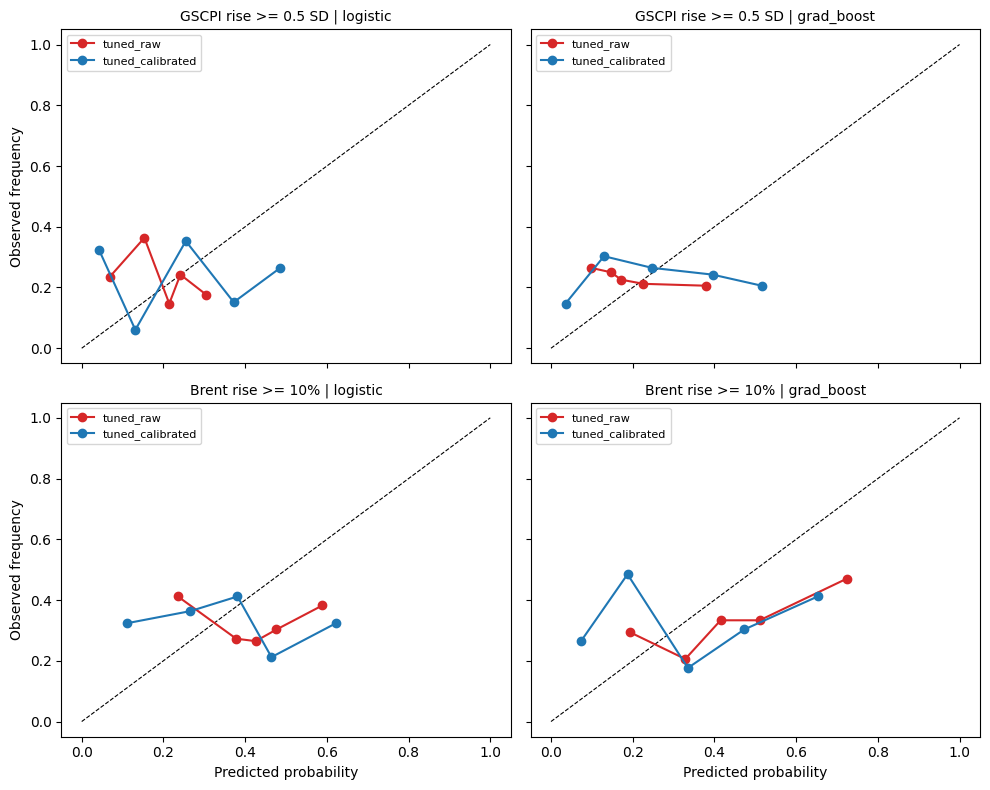

In [4]:
FEATS = ["oni_lag1", "oni_chg3", "nino34_lag1", "brent_ret1", "brent_ret3", "brent_z12", "gscpi_lag1", "gscpi_chg3"]
GRID = {"logistic": [{"C": c} for c in (0.01, 0.1, 1.0, 10.0)],
        "grad_boost": list(ParameterGrid({"max_depth": [2, 3], "learning_rate": [0.03, 0.1], "max_iter": [60, 150]}))}
DEFAULT = {"logistic": {"C": 1.0}, "grad_boost": {"max_depth": 3, "learning_rate": 0.05, "max_iter": 150}}
def make(model, hp):
    if model == "logistic": return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=hp["C"], max_iter=1000))
    return HistGradientBoostingClassifier(random_state=0, **hp)
class Platt:
    def fit(self, p, y):
        self.ok = len(y) >= 30 and len(set(y)) == 2
        if self.ok: self.m = LogisticRegression(C=1e6, max_iter=1000).fit(self._z(p), y)
        return self
    def _z(self, p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p)).reshape(-1, 1)
    def predict(self, p): return self.m.predict_proba(self._z(p))[:, 1] if self.ok else np.asarray(p)
def known_idx(y, a, b): ix = panel.index[(panel.index >= a) & (panel.index <= b)]; return ix[y.reindex(ix).notna().values]
def inner_folds(y, cutoff, last_year):
    folds = []
    for fy in range(last_year - 3, last_year + 1):
        trf = known_idx(y, "1999-01", pd.Period(f"{fy-1}-12", freq="M") - H); vaf = known_idx(y, f"{fy}-01", min(pd.Period(f"{fy}-12", freq="M"), cutoff))
        if y.loc[trf].sum() >= 5 and len(vaf) >= 6: folds.append((trf, vaf))
    return folds
def tune(model, y, cutoff, last_year):
    folds = inner_folds(y, cutoff, last_year)
    if not folds: return DEFAULT[model], None, None
    best, bs = None, np.inf
    for hp in GRID[model]:
        oof_p, oof_y = [], []
        for trf, vaf in folds:
            m = make(model, hp).fit(panel.loc[trf, FEATS], y.loc[trf]); oof_p += list(m.predict_proba(panel.loc[vaf, FEATS])[:, 1]); oof_y += list(y.loc[vaf])
        sc_ = np.mean((np.array(oof_p) - np.array(oof_y)) ** 2)
        if sc_ < bs: bs, best, best_oof = sc_, hp, (np.array(oof_p), np.array(oof_y))
    return best, best_oof[0], best_oof[1]

TARGETS = {"GSCPI rise >= 0.5 SD": "y_gscpi_h3", "Brent rise >= 10%": "y_brent_h3"}
out, hp_log = [], []
t0 = time.time()
for tname, col in TARGETS.items():
    y = panel[col]
    for yr in range(2012, 2026):
        cutoff = pd.Period(f"{yr-1}-12", freq="M") - H; tr = known_idx(y, "1999-01", cutoff); te = known_idx(y, f"{yr}-01", f"{yr}-12")
        if y.loc[tr].sum() < 5 or len(te) == 0: continue
        for model in ("logistic", "grad_boost"):
            md = make(model, DEFAULT[model]).fit(panel.loc[tr, FEATS], y.loc[tr]); out.append(pd.DataFrame({"target": tname, "variant": f"{model}_default", "month": te, "y": y.loc[te].values, "p": md.predict_proba(panel.loc[te, FEATS])[:, 1], "base": y.loc[tr].mean()}))
            hp, op, oy = tune(model, y, cutoff, yr - 1); md = make(model, hp).fit(panel.loc[tr, FEATS], y.loc[tr]); raw = md.predict_proba(panel.loc[te, FEATS])[:, 1]
            cal = Platt().fit(op, oy).predict(raw) if op is not None else raw
            out.append(pd.DataFrame({"target": tname, "variant": f"{model}_tuned_raw", "month": te, "y": y.loc[te].values, "p": raw, "base": y.loc[tr].mean()}))
            out.append(pd.DataFrame({"target": tname, "variant": f"{model}_tuned_calibrated", "month": te, "y": y.loc[te].values, "p": cal, "base": y.loc[tr].mean()}))
            hp_log.append(dict(target=tname, test_year=yr, model=model, **{k: v for k, v in hp.items()}))
print("nested tuning finished in", round(time.time() - t0), "seconds")
tp = pd.concat(out, ignore_index=True); tp.to_csv(f"{BASE}/tuned_predictions.csv", index=False); pd.DataFrame(hp_log).to_csv(f"{BASE}/tuned_hyperparameters_by_year.csv", index=False)

def ece(y, p, bins=5):
    q = pd.qcut(p, bins, duplicates="drop"); g = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q", observed=True)
    return float((g.size() / len(y) * (g["y"].mean() - g["p"].mean()).abs()).sum())
B, BL = 1000, 6; rows = []
for (tname, var), g in tp.groupby(["target", "variant"]):
    g = g.sort_values("month"); y, s_, b_ = g.y.values, g.p.values, g.base.values; n = len(y); ba, bb = [], []
    for _ in range(B):
        st = rng.integers(0, n - BL + 1, size=int(np.ceil(n / BL))); ix = np.concatenate([np.arange(k, k + BL) for k in st])[:n]
        v = auc(y[ix], s_[ix]); ba.append(v) if not np.isnan(v) else None; bb.append(bss(y[ix], s_[ix], b_[ix]))
    perm = np.array([auc(np.roll(y, int(k)), s_) for k in rng.integers(6, n - 6, size=B)]); a0 = auc(y, s_)
    rows.append(dict(target=tname, variant=var, n=n, auc=round(a0, 3), auc_ci95=f"[{np.percentile(ba, 2.5):.2f}, {np.percentile(ba, 97.5):.2f}]", brier_skill=round(bss(y, s_, b_), 3),
                     bss_ci95=f"[{np.percentile(bb, 2.5):.2f}, {np.percentile(bb, 97.5):.2f}]", ece=round(ece(y, s_), 3), p_perm=round((np.sum(perm >= a0) + 1) / (B + 1), 3)))
tr_ = pd.DataFrame(rows); o = tr_.p_perm.rank(method="first").astype(int).sort_values(); run = 0; hol = {}
for i, ix in enumerate(o.index): run = max(run, min(1, (len(tr_) - i) * tr_.p_perm[ix])); hol[ix] = run
tr_["p_holm"] = pd.Series(hol).round(3)
# single-feature benchmarks (no fitting): can the models beat their own best input?
bench = []
for tname, col in TARGETS.items():
    for f in ("gscpi_chg3", "brent_ret3"):
        m_ = panel.loc["2012-01":"2025-12", [f, col]].dropna(); bench.append(dict(target=tname, variant=f"single feature: {f}", n=len(m_), auc=round(auc(m_[col].values, m_[f].values), 3)))
print(tr_.to_string(index=False)); print(pd.DataFrame(bench).to_string(index=False)); tr_.to_csv(f"{BASE}/table_tuned_results.csv", index=False); pd.DataFrame(bench).to_csv(f"{BASE}/table_single_feature_benchmarks.csv", index=False)

fig, axs = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for i, tname in enumerate(TARGETS):
    for j, model in enumerate(("logistic", "grad_boost")):
        ax = axs[i, j]; ax.plot([0, 1], [0, 1], "k--", lw=0.8)
        for var, c in ((f"{model}_tuned_raw", "tab:red"), (f"{model}_tuned_calibrated", "tab:blue")):
            g = tp[(tp.target == tname) & (tp.variant == var)]; r = g.assign(q=pd.qcut(g.p, 5, duplicates="drop")).groupby("q", observed=True).agg(pr=("p", "mean"), ob=("y", "mean"))
            ax.plot(r.pr, r.ob, "o-", color=c, label=var.replace(model + "_", ""))
        ax.set_title(f"{tname} | {model}", fontsize=10); ax.legend(fontsize=8)
for ax in axs[1]: ax.set_xlabel("Predicted probability")
for ax in axs[:, 0]: ax.set_ylabel("Observed frequency")
fig.tight_layout(); fig.savefig(f"{BASE}/fig_reliability_tuned.png", dpi=150); plt.show()

## 4. Final models: train on all labelled data and save

In [5]:
os.makedirs(f"{BASE}/models", exist_ok=True); meta = {}
for tname, col in TARGETS.items():
    y = panel[col]; last_known = y.dropna().index.max(); tr = known_idx(y, "1999-01", last_known)
    for model in ("logistic", "grad_boost"):
        hp, op, oy = tune(model, y, last_known, last_known.year); md = make(model, hp).fit(panel.loc[tr, FEATS], y.loc[tr]); cal = Platt().fit(op, oy) if op is not None else None
        fn = f"models/{model}_{col}.joblib"; joblib.dump({"model": md, "calibrator": cal, "features": FEATS, "hyperparameters": hp, "target": tname, "trained_through": str(last_known)}, f"{BASE}/{fn}")
        meta[f"{model}|{tname}"] = dict(file=fn, hyperparameters={k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in hp.items()}, trained_through=str(last_known), n_train=int(len(tr)), positives=int(y.loc[tr].sum()))
spec = SPECS["G1 baseline DAG"]; mg, mb, _ = fit_spec(spec, "2025-12")
meta["structural_G1"] = dict(gscpi_equation={k: float(v) for k, v in mg.params.items()}, brent_equation={k: float(v) for k, v in mb.params.items()}, fitted_through="2025-12")
json.dump(meta, open(f"{BASE}/models/model_card.json", "w"), indent=2); print(json.dumps(meta, indent=1)[:1400])
print("\nTo reuse a saved model later:  obj = joblib.load(f'{BASE}/models/logistic_y_gscpi_h3.joblib'); p = obj['model'].predict_proba(X[obj['features']])[:,1]; p = obj['calibrator'].predict(p) if obj['calibrator'] else p")
print("REMINDER: tuning and calibration do not create skill that is not in the data; read the confidence intervals above.")

{
 "logistic|GSCPI rise >= 0.5 SD": {
  "file": "models/logistic_y_gscpi_h3.joblib",
  "hyperparameters": {
   "C": 0.01
  },
  "trained_through": "2026-06",
  "n_train": 330,
  "positives": 81
 },
 "grad_boost|GSCPI rise >= 0.5 SD": {
  "file": "models/grad_boost_y_gscpi_h3.joblib",
  "hyperparameters": {
   "learning_rate": 0.03,
   "max_depth": 2.0,
   "max_iter": 60.0
  },
  "trained_through": "2026-06",
  "n_train": 330,
  "positives": 81
 },
 "logistic|Brent rise >= 10%": {
  "file": "models/logistic_y_brent_h3.joblib",
  "hyperparameters": {
   "C": 10.0
  },
  "trained_through": "2026-06",
  "n_train": 330,
  "positives": 137
 },
 "grad_boost|Brent rise >= 10%": {
  "file": "models/grad_boost_y_brent_h3.joblib",
  "hyperparameters": {
   "learning_rate": 0.1,
   "max_depth": 3.0,
   "max_iter": 60.0
  },
  "trained_through": "2026-06",
  "n_train": 330,
  "positives": 137
 },
 "structural_G1": {
  "gscpi_equation": {
   "const": 6.105190719928738e-06,
   "dg": 0.135742983712989